## Bank Marketing Classification Project

### Data Visualization and Preprocessing

In [1]:
# Import required libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Ignore futurewarnings (just to make the project visually better)
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
# Load the dataset
bank_df = pd.read_csv('bank-additional-full.csv', delimiter = ";")

In [3]:
# Explore the data:
# 1. Display the first few rows
bank_df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [7]:
# 2. Get data type information
bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [9]:
# 3. Get summary statistics
bank_df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [11]:
banking = bank_df.drop('y', axis = 1)
bank_target = bank_df['y']

In [13]:
banking['job'].value_counts()

job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

In [15]:
banking['education'].value_counts()

education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64

In [17]:
banking['marital'].value_counts()

marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64

In [19]:
banking['contact'].value_counts()

contact
cellular     26144
telephone    15044
Name: count, dtype: int64

In [21]:
banking['default'].value_counts()

default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

In [23]:
banking['housing'].value_counts()

housing
yes        21576
no         18622
unknown      990
Name: count, dtype: int64

In [25]:
banking['loan'].value_counts()

loan
no         33950
yes         6248
unknown      990
Name: count, dtype: int64

In [27]:
banking['poutcome'].value_counts()

poutcome
nonexistent    35563
failure         4252
success         1373
Name: count, dtype: int64

In [29]:
banking['day_of_week'].value_counts()

day_of_week
thu    8623
mon    8514
wed    8134
tue    8090
fri    7827
Name: count, dtype: int64

In [31]:
# Split data into training and testing sets
bank_train, bank_test, target_train, target_test = train_test_split(banking, bank_target, test_size=0.2, random_state=42)

In [33]:
# Handle missing values (e.g., replace missing values with the mean of the column)
bank_train['housing'].replace('unknown', np.nan, inplace=True)
bank_train['loan'].replace('unknown', np.nan, inplace=True)
bank_train['marital'].replace('unknown', np.nan, inplace=True)
bank_train['education'].replace('unknown', np.nan, inplace=True)
bank_train['job'].replace('unknown', np.nan, inplace=True)


combined = bank_train.copy()
combined['target_train'] = target_train
combined.dropna(inplace=True)
combined = combined[combined['default'] != 'yes']

bank_tr_c = combined.drop('target_train', axis=1)
target_tr_c = combined['target_train']

In [35]:
#Test set data handling same as train set
bank_test['housing'].replace('unknown', np.nan, inplace=True)
bank_test['loan'].replace('unknown', np.nan, inplace=True)
bank_test['marital'].replace('unknown', np.nan, inplace=True)
bank_test['education'].replace('unknown', np.nan, inplace=True)
bank_test['job'].replace('unknown', np.nan, inplace=True)


combined2 = bank_test.copy()
combined2['target_test'] = target_test
combined2.dropna(inplace=True)
combined2 = combined2[combined2['default'] != 'yes']

bank_ts_c = combined2.drop('target_test', axis=1)
target_ts_c = combined2['target_test']

In [37]:
print('target hape', target_tr_c.shape)
print('feature shape', bank_tr_c.shape)

target hape (30566,)
feature shape (30566, 20)


In [39]:
print('target_test hape', target_ts_c.shape)
print('feature_test shape', bank_ts_c.shape)

target_test hape (7676,)
feature_test shape (7676, 20)


In [41]:
bank_tr_c.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30566 entries, 12556 to 15795
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             30566 non-null  int64  
 1   job             30566 non-null  object 
 2   marital         30566 non-null  object 
 3   education       30566 non-null  object 
 4   default         30566 non-null  object 
 5   housing         30566 non-null  object 
 6   loan            30566 non-null  object 
 7   contact         30566 non-null  object 
 8   month           30566 non-null  object 
 9   day_of_week     30566 non-null  object 
 10  duration        30566 non-null  int64  
 11  campaign        30566 non-null  int64  
 12  pdays           30566 non-null  int64  
 13  previous        30566 non-null  int64  
 14  poutcome        30566 non-null  object 
 15  emp.var.rate    30566 non-null  float64
 16  cons.price.idx  30566 non-null  float64
 17  cons.conf.idx   30566 non-null  

In [43]:
# Encoding categorical features (e.g., one-hot encoding)

In [45]:
#Job to numerical form with onehot encoder
onehot_encoder_job = OneHotEncoder()
jobs = onehot_encoder_job.fit_transform(bank_tr_c[['job']])
jobs = jobs.toarray()
bank_tr_c[['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management','retired','self-employed',
           'services','student','technician','unemployed']] = jobs
print(onehot_encoder_job.categories_)

[array(['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management',
       'retired', 'self-employed', 'services', 'student', 'technician',
       'unemployed'], dtype=object)]


In [47]:
#Marital to numerical form with onehot, divorced or married or single
onehot_encoder_mar = OneHotEncoder()
marital = onehot_encoder_mar.fit_transform(bank_tr_c[['marital']])
marital = marital.toarray()
bank_tr_c[['divorced', 'married','single']] = marital
print(onehot_encoder_mar.categories_)

#Handling weekdays and month to numerical form
days = {'mon': 0,'tue': 1, 'wed': 2, 'thu': 3, 'fri': 4}
month = {'jan': 1, 'feb':2, 'mar':3, 'apr':4, 'may':5, 'jun':6, 'jul':7, 'aug':8, 'sep':9, 'oct':10, 'nov':11, 'dec':12} 

bank_tr_c['day.enc'] = bank_tr_c['day_of_week'].map(days)
bank_tr_c['month.enc'] = bank_tr_c['month'].map(month)

#Contact to numerical form with onehot, cellular or telephone
onehot_encoder_con = OneHotEncoder()
contact = onehot_encoder_con.fit_transform(bank_tr_c[['contact']])
contact = contact.toarray()
bank_tr_c[['cellular', 'telephone']] = contact

#Education to numerical form with onehot
onehot_encoder_ed = OneHotEncoder()
education = onehot_encoder_ed.fit_transform(bank_tr_c[['education']])
education = education.toarray()
bank_tr_c[['basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.cource','university.degree']] = education 


#Default to numerical form with onehot, no or unknown (only 3 yes arwears were removed from the dataset
onehot_encoder_def = OneHotEncoder()
default = onehot_encoder_def.fit_transform(bank_tr_c[['default']])
default = default.toarray()
bank_tr_c[['default.no', 'default.unknown']] = default

#housing to numerical form with onehot, no on yes
onehot_encoder_hou = OneHotEncoder()
housing = onehot_encoder_hou.fit_transform(bank_tr_c[['housing']])
housing = housing.toarray()
bank_tr_c[['housing.no', 'housing.yes']] = housing


#Loan to numerical form with onehot, no or yes
onehot_encoder_lo = OneHotEncoder()
loan = onehot_encoder_lo.fit_transform(bank_tr_c[['loan']])
loan = loan.toarray()
bank_tr_c[['loan.no', 'loan.yes']] = loan

#Poutcome to numerical form with onehot, nonexistent or failure or success
onehot_encoder_pou = OneHotEncoder()
poutcome = onehot_encoder_pou.fit_transform(bank_tr_c[['poutcome']])
poutcome = poutcome.toarray()
bank_tr_c[['poutcome.failure', 'poutcome.nonexistent', 'poutcome.success']] = poutcome
print(onehot_encoder_pou.categories_)


[array(['divorced', 'married', 'single'], dtype=object)]
[array(['failure', 'nonexistent', 'success'], dtype=object)]


In [49]:
bank_ts_c

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
32884,57,technician,married,high.school,no,no,yes,cellular,may,mon,371,1,999,1,failure,-1.8,92.893,-46.2,1.299,5099.1
32206,33,blue-collar,married,basic.9y,no,no,no,cellular,may,fri,52,1,999,1,failure,-1.8,92.893,-46.2,1.313,5099.1
9403,36,admin.,married,high.school,no,no,no,telephone,jun,fri,355,4,999,0,nonexistent,1.4,94.465,-41.8,4.967,5228.1
14020,27,housemaid,married,high.school,no,yes,no,cellular,jul,fri,189,2,999,0,nonexistent,1.4,93.918,-42.7,4.963,5228.1
17201,58,retired,married,professional.course,no,yes,yes,cellular,jul,fri,605,1,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12322,27,services,married,high.school,unknown,no,no,telephone,jul,fri,584,1,999,0,nonexistent,1.4,93.918,-42.7,4.959,5228.1
23440,41,technician,divorced,professional.course,no,no,no,cellular,aug,wed,167,7,999,0,nonexistent,1.4,93.444,-36.1,4.964,5228.1
29431,46,entrepreneur,single,university.degree,no,yes,yes,cellular,apr,mon,142,12,999,1,failure,-1.8,93.075,-47.1,1.405,5099.1
16627,31,admin.,single,university.degree,no,yes,no,cellular,jul,wed,1327,2,999,0,nonexistent,1.4,93.918,-42.7,4.963,5228.1


In [51]:
#Test set 

#Job to numerical form with one hot encoder
jobs = onehot_encoder_job.transform(bank_ts_c[['job']])
jobs = jobs.toarray()
bank_ts_c[['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management','retired','self-employed',
           'services','student','technician','unemployed']] = jobs

In [53]:


#Marital to numerical form with onehot, divorced or married or single
marital = onehot_encoder_mar.transform(bank_ts_c[['marital']])
marital = marital.toarray()
bank_ts_c[['divorced', 'married','single']] = marital

#Days and months into numerical form
bank_ts_c['day.enc'] = bank_ts_c['day_of_week'].map(days)
bank_ts_c['month.enc'] = bank_ts_c['month'].map(month)

#Contact to numerical form with onehot, cellular or telephone
contact = onehot_encoder_con.transform(bank_ts_c[['contact']])
contact = contact.toarray()
bank_ts_c[['cellular', 'telephone']] = contact

#Education to numerical form with onehot
education = onehot_encoder_ed.transform(bank_ts_c[['education']])
education = education.toarray()
bank_ts_c[['basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.cource','university.degree']] = education 


#Default to numerical form with onehot, no or unknown (only 3 yes arwears were removed from the dataset
default = onehot_encoder_def.transform(bank_ts_c[['default']])
default = default.toarray()
bank_ts_c[['default.no', 'default.unknown']] = default

#housing to numerical form with onehot, no on yes
housing = onehot_encoder_hou.transform(bank_ts_c[['housing']])
housing = housing.toarray()
bank_ts_c[['housing.no', 'housing.yes']] = housing


#Loan to numerical form with onehot, no or yes
loan = onehot_encoder_lo.transform(bank_ts_c[['loan']])
loan = loan.toarray()
bank_ts_c[['loan.no', 'loan.yes']] = loan

#Poutcome to numerical form with onehot, nonexistent or failure or success
poutcome = onehot_encoder_pou.transform(bank_ts_c[['poutcome']])
poutcome = poutcome.toarray()
bank_ts_c[['poutcome.failure', 'poutcome.nonexistent', 'poutcome.success']] = poutcome


In [55]:
#Drop all old categorical column
bank_tr_c.drop(columns=['marital', 'contact', 'job', 'day_of_week', 'month', 'education','default', 'housing', 'loan','poutcome'], inplace=True)

In [57]:
#Drop test set old columns
bank_ts_c.drop(columns=['marital', 'contact', 'job', 'day_of_week', 'month', 'education','default', 'housing', 'loan','poutcome'], inplace=True)

In [59]:
#Check columns and their types
bank_tr_c.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30566 entries, 12556 to 15795
Data columns (total 44 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   30566 non-null  int64  
 1   duration              30566 non-null  int64  
 2   campaign              30566 non-null  int64  
 3   pdays                 30566 non-null  int64  
 4   previous              30566 non-null  int64  
 5   emp.var.rate          30566 non-null  float64
 6   cons.price.idx        30566 non-null  float64
 7   cons.conf.idx         30566 non-null  float64
 8   euribor3m             30566 non-null  float64
 9   nr.employed           30566 non-null  float64
 10  admin.                30566 non-null  float64
 11  blue-collar           30566 non-null  float64
 12  entrepreneur          30566 non-null  float64
 13  housemaid             30566 non-null  float64
 14  management            30566 non-null  float64
 15  retired             

In [61]:
#target train set to numerical
target_tr_c.replace('yes', 1, inplace=True)
target_tr_c.replace('no', 0, inplace=True)

#target test set to numerical
target_ts_c.replace('yes', 1, inplace=True)
target_ts_c.replace('no', 0, inplace=True)

In [63]:
# Data Scaling (normalize numerical features)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
bank_tr_c = scaler.fit_transform(bank_tr_c)
bank_ts_c = scaler.transform(bank_ts_c)

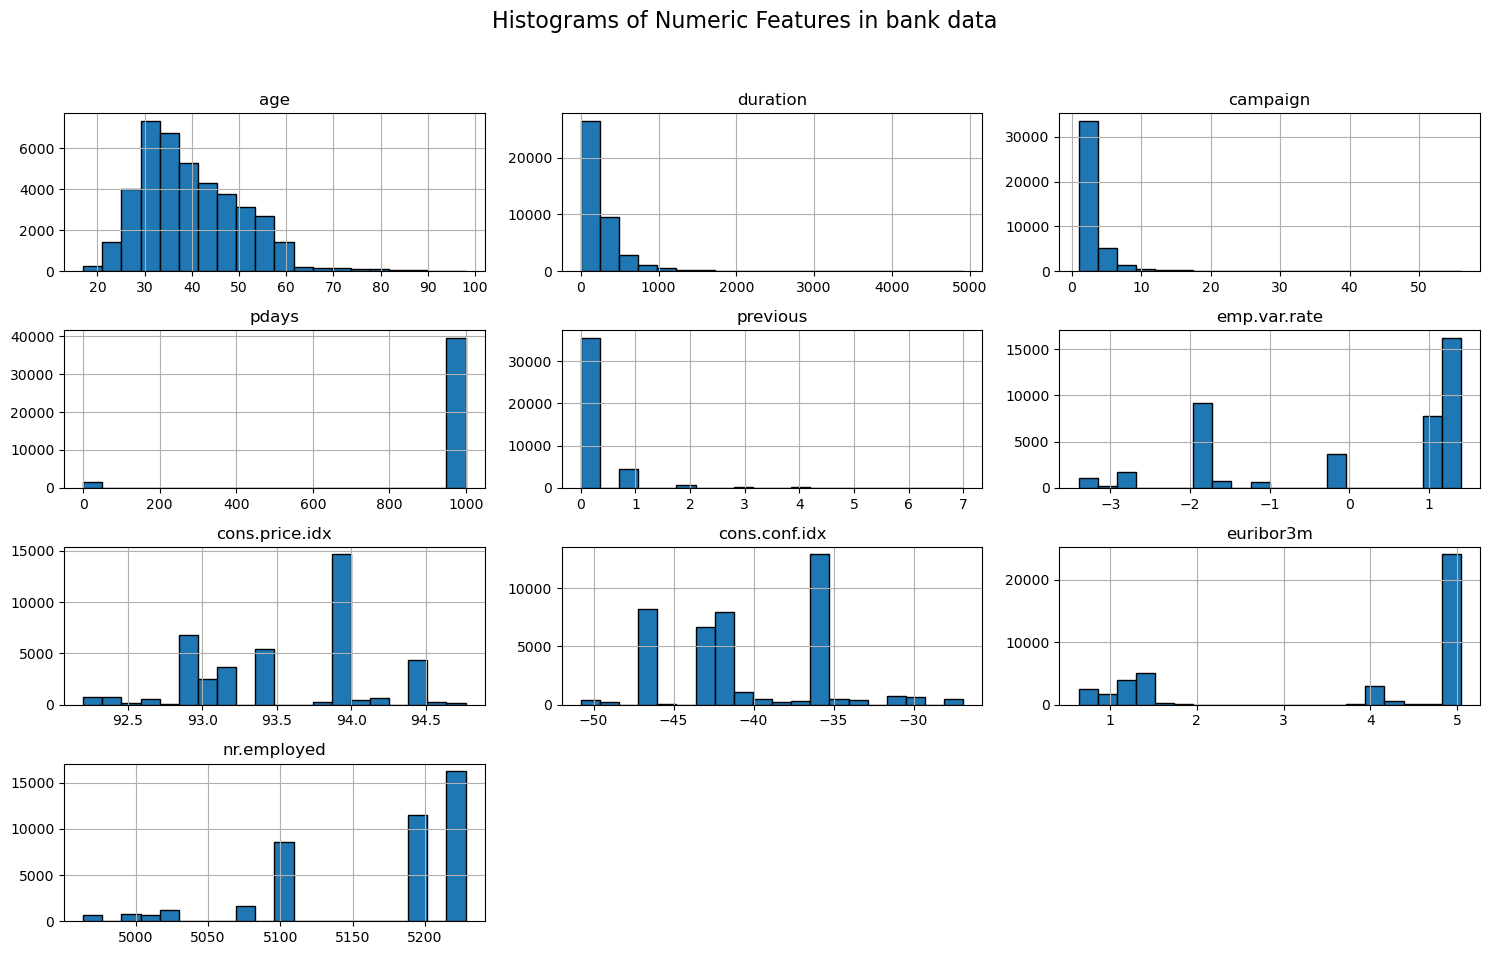

AttributeError: 'numpy.ndarray' object has no attribute 'corr'

<Figure size 1200x1000 with 0 Axes>

In [88]:
# Data Visualization (e.g., histograms, box plots, and correlation matrices)
import seaborn as sns

# Histograms for numeric columns
bank_df.hist(figsize=(15, 10), bins=20, edgecolor='black')
plt.suptitle('Histograms of Numeric Features in bank data', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# Correlation matrix with heatmap
plt.figure(figsize=(12, 10))
corr_matrix = bank_df[numerical_columns].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Correlation Matrix Heatmap of Numeric Features')
plt.tight_layout()
plt.show()

### Training Three Classification Models


In [67]:
# Step 2: Training Three Classification Models

#Logistic Regression:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression()
log_reg.fit(bank_tr_c, target_tr_c)

LogisticRegression()

In [69]:
#Decision tree:
from sklearn.tree import DecisionTreeRegressor
tree_reg = DecisionTreeRegressor(random_state=42)
tree_reg.fit(bank_tr_c, target_tr_c)

DecisionTreeRegressor(random_state=42)

In [71]:
#K-nearest neighborhood (KNN):
from sklearn.neighbors import KNeighborsClassifier 
knn = KNeighborsClassifier(n_neighbors=50) 
knn.fit(bank_tr_c, target_tr_c)

KNeighborsClassifier(n_neighbors=50)

In [73]:
#Model training
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

#Logistic Regression:

#prediction
y_pred_log=log_reg.predict(bank_ts_c)

#evaluation
accuracy_log=accuracy_score(target_ts_c, y_pred_log)
precision_log=precision_score(target_ts_c, y_pred_log)
recall_log=recall_score(target_ts_c, y_pred_log)
f1_log=f1_score(target_ts_c, y_pred_log)
ROC_log=roc_auc_score(target_ts_c, y_pred_log)

print('Logistic Regression accuracy score:', accuracy_log)
print('Logistic Regression precision score:', precision_log)
print('Logistic Regression recall score:', recall_log)
print('Logistic Regression F1 score:', f1_log)
print('Logistic Regression ROC-AUC score:', ROC_log)

Logistic Regression accuracy score: 0.9115424700364774
Logistic Regression precision score: 0.6654135338345865
Logistic Regression recall score: 0.41403508771929826
Logistic Regression F1 score: 0.5104542177361211
Logistic Regression ROC-AUC score: 0.6939696036749254


In [75]:
#Decision Tree:

#prediction
y_pred_tree=tree_reg.predict(bank_ts_c)

#evaluation
accuracy_tree=accuracy_score(target_ts_c, y_pred_tree)
precision_tree=precision_score(target_ts_c, y_pred_tree)
recall_tree=recall_score(target_ts_c, y_pred_tree)
f1_tree=f1_score(target_ts_c, y_pred_tree)
ROC_tree=roc_auc_score(target_ts_c, y_pred_tree)

print('Decision tree accuracy score:', accuracy_tree)
print('Decision tree precision score:', precision_tree)
print('Decision tree recall score:', recall_tree)
print('Decision tree F1 score:', f1_tree)
print('Decision tree ROC-AUC score:', ROC_tree)

Decision tree accuracy score: 0.8895257946847316
Decision tree precision score: 0.5041322314049587
Decision tree recall score: 0.4994152046783626
Decision tree F1 score: 0.5017626321974148
Decision tree ROC-AUC score: 0.7189203277460132


In [77]:
#K-nearest neighborhood (KNN):

#prediction
y_pred_knn=knn.predict(bank_ts_c)

#evaluation
accuracy_knn=accuracy_score(target_ts_c, y_pred_knn)
precision_knn=precision_score(target_ts_c, y_pred_knn)
recall_knn=recall_score(target_ts_c, y_pred_knn)
f1_knn=f1_score(target_ts_c, y_pred_knn)
ROC_knn=roc_auc_score(target_ts_c, y_pred_knn)

print('KNN accuracy score:', accuracy_knn)
print('KNN precision score:', precision_knn)
print('KNN recall score:', recall_knn)
print('KNN F1 score:', f1_knn)
print('KNN ROC-AUC score:', ROC_knn)

KNN accuracy score: 0.8986451276706618
KNN precision score: 0.6558704453441295
KNN recall score: 0.18947368421052632
KNN F1 score: 0.294010889292196
KNN ROC-AUC score: 0.5885060841518839


### Model Tuning and Validation (Including ROC Curve Analysis and Model Selection Rationale)

In [82]:
# Model Tuning and Validation

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

# Defining parameter grids for tuning
log_params = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['liblinear']
}

tree_params = {
    'max_depth': [3, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

knn_params = {
    'n_neighbors': [3, 5, 7, 10, 15, 20, 30],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

# Grid search, 5 fold cross validation for logistic regression
log_grid = GridSearchCV(LogisticRegression(), log_params, cv=5, scoring='roc_auc')
log_grid.fit(bank_tr_c, target_tr_c)

# Decision tree grid search
tree_grid = GridSearchCV(DecisionTreeClassifier(random_state=42), tree_params, cv=5, scoring='roc_auc')
tree_grid.fit(bank_tr_c, target_tr_c)

# Grid search for KNN
knn_grid = GridSearchCV(KNeighborsClassifier(), knn_params, cv=5, scoring='roc_auc')
knn_grid.fit(bank_tr_c, target_tr_c)

# Storing best estimators
log_best = log_grid.best_estimator_
tree_best = tree_grid.best_estimator_
knn_best = knn_grid.best_estimator_

print(f"Best Logistic Regression CV AUC: {log_grid.best_score_:.4f}")
print(f"Best Decision Tree CV AUC: {tree_grid.best_score_:.4f}")
print(f"Best KNN CV AUC: {knn_grid.best_score_:.4f}")


Best Logistic Regression CV AUC: 0.9267
Best Decision Tree CV AUC: 0.9235
Best KNN CV AUC: 0.8766


In [90]:
# Perform ROC curve analysis and calculate AUC-ROC for each model

# Predicting probabilities for ROC curve
y_prob_log = log_best.predict_proba(bank_ts_c)[:, 1]
y_prob_tree = tree_best.predict_proba(bank_ts_c)[:, 1]
y_prob_knn = knn_best.predict_proba(bank_ts_c)[:, 1]

# Calculating ROC AUC scores
auc_log = roc_auc_score(target_ts_c, y_prob_log)
auc_tree = roc_auc_score(target_ts_c, y_prob_tree)
auc_knn = roc_auc_score(target_ts_c, y_prob_knn)

print(f"Logistic Regression AUC: {auc_log:.4f}")
print(f"Decision Tree AUC: {auc_tree:.4f}")
print(f"KNN AUC: {auc_knn:.4f}")


Logistic Regression AUC: 0.9318
Decision Tree AUC: 0.9222
KNN AUC: 0.8860


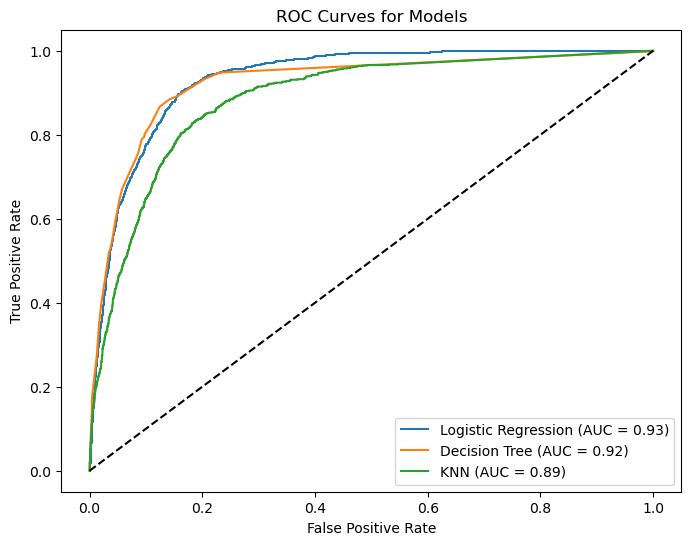

In [92]:
# Visualize ROC curves

# Computing values for the ROC curve
fpr_log, tpr_log, _ = roc_curve(target_ts_c, y_prob_log)
fpr_tree, tpr_tree, _ = roc_curve(target_ts_c, y_prob_tree)
fpr_knn, tpr_knn, _ = roc_curve(target_ts_c, y_prob_knn)

plt.figure(figsize=(8,6))
plt.plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC = {auc_log:.2f})')
plt.plot(fpr_tree, tpr_tree, label=f'Decision Tree (AUC = {auc_tree:.2f})')
plt.plot(fpr_knn, tpr_knn, label=f'KNN (AUC = {auc_knn:.2f})')

plt.plot([0,1], [0,1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Models')
plt.legend()
plt.show()


In [94]:
# Threshold Selection (You can manually select a threshold based on ROC analysis)

# Thresholds and TPR/FPR
fpr, tpr, thresholds = roc_curve(target_ts_c, y_prob_log)

# Find the best threshold that balances true positive and false positive rates
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

print(f"Optimal threshold for Logistic Regression: {optimal_threshold:.4f}")

y_pred_optimal = (y_prob_log >= optimal_threshold).astype(int)

Optimal threshold for Logistic Regression: 0.0985


In [96]:
# Final Model Selection (Select the best-performing model based on AUC-ROC)

# I did it this way so its easy to test other models without changing the whole code
final_model = log_grid.best_estimator_
final_model_name = "Decision Tree"
print(f"Selected final model: {final_model_name} with AUC = {max(auc_log, auc_tree, auc_knn):.4f}")

Selected final model: Decision Tree with AUC = 0.9318


In [98]:
# Model Testing (Evaluate the selected model on the testing dataset)

# Getting predicted probabilities and final class predictions from the model

y_prob_final = final_model.predict_proba(bank_ts_c)[:, 1]
y_pred_final = final_model.predict(bank_ts_c)

# Evaluation metrics
acc_final = accuracy_score(target_ts_c, y_pred_final)
prec_final = precision_score(target_ts_c, y_pred_final)
recall_final = recall_score(target_ts_c, y_pred_final)
f1_final = f1_score(target_ts_c, y_pred_final)
auc_final = roc_auc_score(target_ts_c, y_prob_final)

print(f"{final_model_name} Test Accuracy: {acc_final:.4f}")
print(f"{final_model_name} Test Precision: {prec_final:.4f}")
print(f"{final_model_name} Test Recall: {recall_final:.4f}")
print(f"{final_model_name} Test F1-Score: {f1_final:.4f}")
print(f"{final_model_name} Test ROC-AUC: {auc_final:.4f}")


Decision Tree Test Accuracy: 0.9115
Decision Tree Test Precision: 0.6654
Decision Tree Test Recall: 0.4140
Decision Tree Test F1-Score: 0.5105
Decision Tree Test ROC-AUC: 0.9318
